# Vision-only behavior cloning

Run the cells in order. Explanations introduce each step; code and saved outputs are preserved.


### Import tools

Load PyTorch before simulator libraries and locate the project. This notebook trains and validates the vision-only behavior-cloning baseline.


In [52]:
from pathlib import Path
import hashlib
import json

import torch
import torchvision

import h5py
import numpy as np

from torch.utils.data import Dataset, DataLoader

project_dir = Path.home() / "t2-project"
config_dir = project_dir / "configs" / "data_preparation"

print("PyTorch:", torch.__version__)
print("Project:", project_dir)

PyTorch: 2.14.1+cu130
Project: /home/njmcmil/t2-project


### Load saved preparation

Read the existing split manifest and normalization. Verify their fingerprint and next-action convention; do not create a new split for this model.


In [53]:
manifest_path = config_dir / "split_manifest.json"
normalization_path = config_dir / "action_normalization.json"

manifest_bytes = manifest_path.read_bytes()
manifest = json.loads(manifest_bytes)

normalization = json.loads(
    normalization_path.read_text(encoding="utf-8")
)

actual_hash = hashlib.sha256(manifest_bytes).hexdigest()

assert actual_hash == normalization["manifest_sha256"], (
    "The normalization file does not match this split manifest."
)

assert normalization["fit_split"] == "train"

assert manifest["preprocessing"]["action_target"] == (
    "actions[t + 1] for observation[t]"
)

camera_names = manifest["preprocessing"]["cameras"]

print("Cameras:", camera_names)
print("Training examples:", normalization["training_pairs"])
print("Preparation files match.")

Cameras: ['agentview_rgb', 'eye_in_hand_rgb']
Training examples: 5442
Preparation files match.


### Define the Dataset

Describe how to retrieve one example. The index identifies its task, episode, and time step. Read both images, pair them with action[t + 1], and apply the saved preprocessing.


In [54]:
class LiberoDataset(Dataset):
    def __init__(self, project_dir, manifest, normalization, split):
        self.project_dir = Path(project_dir)
        self.manifest = manifest
        self.split = split
        self.camera_names = manifest["preprocessing"]["cameras"]

        self.action_mean = np.asarray(
            normalization["mean"],
            dtype=np.float32
        )

        self.action_scale = np.asarray(
            normalization["scale"],
            dtype=np.float32
        )

        self.index = []

        for task, episode_names in manifest["splits"][split].items():
            path = (
                self.project_dir
                / manifest["tasks"][task]["file"]
            )

            with h5py.File(path, "r") as demo_file:
                for episode_name in episode_names:
                    action_count = len(
                        demo_file["data"][episode_name]["actions"]
                    )

                    for timestep in range(action_count - 1):
                        self.index.append(
                            (task, episode_name, timestep)
                        )

    def __len__(self):
        return len(self.index)

    def __getitem__(self, index):
        task, episode_name, timestep = self.index[index]

        path = (
            self.project_dir
            / self.manifest["tasks"][task]["file"]
        )

        images = {}

        with h5py.File(path, "r") as demo_file:
            episode = demo_file["data"][episode_name]

            for camera in self.camera_names:
                image = episode["obs"][camera][timestep]

                image = image.astype(np.float32) / 255.0
                image = image.transpose(2, 0, 1)
                image = np.ascontiguousarray(image)

                images[camera] = torch.from_numpy(image)

            action = episode["actions"][timestep + 1]
            action = action.astype(np.float32)

        action = (
            action - self.action_mean
        ) / self.action_scale

        return {
            "images": images,
            "action": torch.from_numpy(action),
            "instruction": (
                self.manifest["tasks"][task]["language_instruction"]
            ),
            "task": task,
            "episode": episode_name,
            "timestep": timestep,
        }

### Create training and validation datasets

Build separate Dataset objects using the same preprocessing but different episode lists. Keep the test split out of model selection.


In [55]:
train_dataset = LiberoDataset(
    project_dir,
    manifest,
    normalization,
    split="train"
)

validation_dataset = LiberoDataset(
    project_dir,
    manifest,
    normalization,
    split="validation"
)

assert len(train_dataset) == normalization["training_pairs"]

expected_validation_count = sum(
    counts["usable_pairs"]
    for counts in manifest["counts"]["validation"].values()
)

assert len(validation_dataset) == expected_validation_count

print("Training examples:", len(train_dataset))
print("Validation examples:", len(validation_dataset))

Training examples: 5442
Validation examples: 1152


### Check one example

Verify image shape, pixel range, numeric type, and action shape. One example has no batch dimension yet.


In [56]:
sample = train_dataset[0]

for camera, image in sample["images"].items():
    print(camera, image.shape, image.dtype)

    assert image.shape == (3, 128, 128)
    assert image.dtype == torch.float32
    assert torch.isfinite(image).all()
    assert image.min().item() >= 0
    assert image.max().item() <= 1

print("Action:", sample["action"].shape)
print("Instruction:", sample["instruction"])
print("Episode:", sample["episode"])
print("Time step:", sample["timestep"])

assert sample["action"].shape == (7,)
assert sample["action"].dtype == torch.float32
assert torch.isfinite(sample["action"]).all()

agentview_rgb torch.Size([3, 128, 128]) torch.float32
eye_in_hand_rgb torch.Size([3, 128, 128]) torch.float32
Action: torch.Size([7])
Instruction: put the bowl on the plate
Episode: demo_5
Time step: 0


### Create DataLoaders

Group examples into batches of up to 32. Shuffle training examples, keep validation ordering stable, and retain the smaller final batch.


In [57]:
batch_size = 32

shuffle_generator = torch.Generator()
shuffle_generator.manual_seed(manifest["seed"])

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    generator=shuffle_generator,
    num_workers=0,
    drop_last=False
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0,
    drop_last=False
)

print("Training batches per epoch:", len(train_loader))
print("Validation batches:", len(validation_loader))

Training batches per epoch: 171
Validation batches: 36


### Check one batch

Retrieve a batch and confirm image shapes (32, 3, 128, 128) and action shape (32, 7). This checks the loading pipeline, not model quality.


In [58]:
batch = next(iter(train_loader))

for camera, images in batch["images"].items():
    print(camera, images.shape)

    assert images.shape == (32, 3, 128, 128)

print("Actions:", batch["action"].shape)
print("Instructions:", len(batch["instruction"]))

assert batch["action"].shape == (32, 7)

print("Dataset and DataLoader batch check passed.")

agentview_rgb torch.Size([32, 3, 128, 128])
eye_in_hand_rgb torch.Size([32, 3, 128, 128])
Actions: torch.Size([32, 7])
Instructions: 32
Dataset and DataLoader batch check passed.


### Select the computation device

Choose CUDA when available, seed model randomness, and run a small calculation to confirm the device works.


In [59]:
from torch import nn

training_seed = 0

torch.manual_seed(training_seed)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(training_seed)
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

print("Device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

# Check that actual computation works on this device.
device_test = torch.ones(4, device=device)
print("Device calculation:", (device_test * 2).sum().item())

Device: cuda
GPU: NVIDIA GeForce RTX 5070
Device calculation: 8.0


### Define the vision encoder

Use three convolution layers to turn RGB images into spatial feature maps. ReLU introduces nonlinear behavior; stride 2 reduces spatial dimensions.


In [60]:
class VisionEncoder(nn.Module):
    def __init__(self):
        super().__init__()

        self.convolutions = nn.Sequential(
            nn.Conv2d(
                in_channels=3,
                out_channels=16,
                kernel_size=3,
                stride=2,
                padding=1
            ),
            nn.ReLU(),

            nn.Conv2d(
                in_channels=16,
                out_channels=32,
                kernel_size=3,
                stride=2,
                padding=1
            ),
            nn.ReLU(),

            nn.Conv2d(
                in_channels=32,
                out_channels=64,
                kernel_size=3,
                stride=2,
                padding=1
            ),
            nn.ReLU(),
        )

    def forward(self, images):
        return self.convolutions(images)

### Define the vision-only policy

Apply shared encoder weights to both cameras, pool their features, and concatenate them. The action head predicts seven normalized commands. This baseline does not receive language; average pooling is not GridS.


In [61]:
class VisionOnlyPolicy(nn.Module):
    def __init__(self, camera_names):
        super().__init__()

        self.camera_names = list(camera_names)

        self.encoder = VisionEncoder()

        self.pool = nn.AdaptiveAvgPool2d((4, 4))

        features_per_camera = 64 * 4 * 4

        combined_features = (
            len(self.camera_names) * features_per_camera
        )

        self.action_head = nn.Sequential(
            nn.Linear(combined_features, 256),
            nn.ReLU(),
            nn.Linear(256, 7),
        )

    def forward(self, images):
        camera_features = []

        for camera in self.camera_names:
            feature_map = self.encoder(images[camera])

            pooled_features = self.pool(feature_map)

            flat_features = pooled_features.flatten(start_dim=1)

            camera_features.append(flat_features)

        combined = torch.cat(camera_features, dim=1)

        return self.action_head(combined)

### Check the forward pass

Create a randomly initialized model and verify that its predictions match the target shape. Correct dimensions do not establish useful predictions.


In [62]:
model = VisionOnlyPolicy(camera_names).to(device)

parameter_count = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print("Trainable parameters:", parameter_count)

example_batch = next(iter(train_loader))

example_images = {
    camera: example_batch["images"][camera].to(device)
    for camera in camera_names
}

example_targets = example_batch["action"].to(device)

model.eval()

with torch.no_grad():
    predictions = model(example_images)

print("Predictions:", predictions.shape)
print("Targets:", example_targets.shape)

assert predictions.shape == example_targets.shape
assert torch.isfinite(predictions).all()

print("Model forward pass succeeded.")

Trainable parameters: 549927
Predictions: torch.Size([32, 7])
Targets: torch.Size([32, 7])
Model forward pass succeeded.


### Define loss and optimizer

Mean squared error measures normalized-action prediction error. Adam will update model parameters using gradients; constructing it does not train the model.


In [63]:
loss_function = nn.MSELoss()

learning_rate = 1e-3

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=learning_rate
)

with torch.no_grad():
    initial_loss = loss_function(
        predictions,
        example_targets
    )

print("Initial batch MSE:", initial_loss.item())

Initial batch MSE: 0.8454562425613403


### Test one training update

Predict, calculate loss, compute gradients, and update weights once. This diagnostic uses a training batch. The formal pilot below starts from a fresh model.


In [64]:
model.train()

optimizer.zero_grad(set_to_none=True)

predictions = model(example_images)

loss = loss_function(predictions, example_targets)

assert torch.isfinite(loss)

loss.backward()

optimizer.step()

print("Loss before this update:", loss.item())

model.eval()

with torch.no_grad():
    predictions_after = model(example_images)

    loss_after = loss_function(
        predictions_after,
        example_targets
    )

print("Loss after this update:", loss_after.item())

Loss before this update: 0.8454562425613403
Loss after this update: 0.8279423117637634


### Initialize the pilot run

Create a fresh model, optimizer, shuffle sequence, and unique output folder. Save the run settings and exact preparation artifacts. Rerunning this cell starts a new experiment.


In [65]:
from datetime import datetime, timezone

num_epochs = 10
learning_rate = 1e-3
training_seed = 0

torch.manual_seed(training_seed)

if device.type == "cuda":
    torch.cuda.manual_seed_all(training_seed)

# Recreate the loader so its shuffle sequence starts fresh.
shuffle_generator = torch.Generator()
shuffle_generator.manual_seed(training_seed)

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    generator=shuffle_generator,
    num_workers=0,
    drop_last=False
)

# Discard the model used for the one-update diagnostic.
model = VisionOnlyPolicy(camera_names).to(device)

loss_function = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=learning_rate
)

run_name = datetime.now(timezone.utc).strftime(
    "vision_only_seed0_%Y%m%dT%H%M%S_%fZ"
)

run_dir = project_dir / "runs" / run_name
run_dir.mkdir(parents=True, exist_ok=False)

run_config = {
    "variant": "vision_only",
    "purpose": "10-epoch pilot",
    "training_seed": training_seed,
    "epochs": num_epochs,
    "batch_size": batch_size,
    "learning_rate": learning_rate,
    "optimizer": "Adam",
    "loss": "MSE on normalized actions",
    "cameras": list(camera_names),
    "encoder_channels": [16, 32, 64],
    "pool_shape": [4, 4],
    "head_hidden_size": 256,
    "action_size": 7,
    "manifest_sha256": actual_hash,
    "training_examples": len(train_dataset),
    "validation_examples": len(validation_dataset),
    "torch_version": str(torch.__version__),
    "device": str(device),
}

(run_dir / "config.json").write_text(
    json.dumps(run_config, indent=2),
    encoding="utf-8"
)

# Keep the exact preparation used by this run.
(run_dir / "split_manifest.json").write_bytes(manifest_bytes)

(run_dir / "action_normalization.json").write_text(
    json.dumps(normalization, indent=2),
    encoding="utf-8"
)

print("Run folder:", run_dir)
print("Fresh model and optimizer are ready.")

Run folder: /home/njmcmil/t2-project/runs/vision_only_seed0_20261117T204733_783686Z
Fresh model and optimizer are ready.


### Define one training epoch

Pass through all training batches and update weights. Weight batch losses by batch size so the small final batch does not receive disproportionate influence.


In [66]:
import time
import math


def train_one_epoch(model, loader, optimizer, loss_function, device):
    model.train()

    total_loss = 0.0
    total_examples = 0

    for batch_number, batch in enumerate(loader, start=1):
        images = {
            camera: batch["images"][camera].to(device)
            for camera in camera_names
        }

        targets = batch["action"].to(device)

        optimizer.zero_grad(set_to_none=True)

        predictions = model(images)
        loss = loss_function(predictions, targets)

        if not torch.isfinite(loss).item():
            raise RuntimeError("Training loss became non-finite.")

        loss.backward()
        optimizer.step()

        examples_in_batch = targets.shape[0]

        total_loss += loss.item() * examples_in_batch
        total_examples += examples_in_batch

        if batch_number == 1 or batch_number % 25 == 0:
            print(
                f"  Batch {batch_number}/{len(loader)}"
                f" | mean training loss so far:"
                f" {total_loss / total_examples:.5f}",
                flush=True
            )

    return total_loss / total_examples

### Define validation

Measure loss without gradients or weight updates. Validation guides model selection; it is not autonomous simulator evaluation.


In [67]:
def evaluate_loss(model, loader, loss_function, device):
    model.eval()

    total_loss = 0.0
    total_examples = 0

    with torch.no_grad():
        for batch in loader:
            images = {
                camera: batch["images"][camera].to(device)
                for camera in camera_names
            }

            targets = batch["action"].to(device)

            predictions = model(images)
            loss = loss_function(predictions, targets)

            if not torch.isfinite(loss).item():
                raise RuntimeError("Validation loss became non-finite.")

            examples_in_batch = targets.shape[0]

            total_loss += loss.item() * examples_in_batch
            total_examples += examples_in_batch

    return total_loss / total_examples

### Train and select a checkpoint

Run the 10-epoch pilot, validate after each epoch, and save loss history. Save model weights whenever validation loss improves. This checkpoint supports inference but is not an exact training-resume snapshot.


In [68]:
history = []
best_validation_loss = float("inf")
best_epoch = None

checkpoint_path = run_dir / "best_model.pt"

for epoch in range(1, num_epochs + 1):
    print(f"\nEpoch {epoch}/{num_epochs}", flush=True)

    start_time = time.perf_counter()

    training_loss = train_one_epoch(
        model,
        train_loader,
        optimizer,
        loss_function,
        device
    )

    validation_loss = evaluate_loss(
        model,
        validation_loader,
        loss_function,
        device
    )

    elapsed_seconds = time.perf_counter() - start_time

    record = {
        "epoch": epoch,
        "training_loss": training_loss,
        "validation_loss": validation_loss,
        "seconds": elapsed_seconds,
    }

    history.append(record)

    # Save progress after every completed epoch.
    (run_dir / "history.json").write_text(
        json.dumps(history, indent=2),
        encoding="utf-8"
    )

    improved = validation_loss < best_validation_loss

    if improved:
        best_validation_loss = validation_loss
        best_epoch = epoch

        checkpoint = {
            "model_state_dict": {
                name: value.detach().cpu().clone()
                for name, value in model.state_dict().items()
            },
            "epoch": epoch,
            "validation_loss": validation_loss,
            "config": run_config,
            "normalization": normalization,
        }

        torch.save(checkpoint, checkpoint_path)

    print(
        f"Train MSE: {training_loss:.5f}"
        f" | Validation MSE: {validation_loss:.5f}"
        f" | Time: {elapsed_seconds:.1f}s"
        f" | Saved best: {improved}",
        flush=True
    )

assert best_epoch is not None
assert math.isfinite(best_validation_loss)
assert checkpoint_path.is_file()

print("\nTraining finished.")
print("Best epoch:", best_epoch)
print("Best validation MSE:", best_validation_loss)
print("Saved checkpoint:", checkpoint_path)


Epoch 1/10
  Batch 1/171 | mean training loss so far: 1.02343
  Batch 25/171 | mean training loss so far: 0.97762
  Batch 50/171 | mean training loss so far: 0.98562
  Batch 75/171 | mean training loss so far: 0.92740
  Batch 100/171 | mean training loss so far: 0.87935
  Batch 125/171 | mean training loss so far: 0.83441
  Batch 150/171 | mean training loss so far: 0.79816
Train MSE: 0.77684 | Validation MSE: 0.63987 | Time: 6.3s | Saved best: True

Epoch 2/10
  Batch 1/171 | mean training loss so far: 0.66723
  Batch 25/171 | mean training loss so far: 0.65750
  Batch 50/171 | mean training loss so far: 0.60225
  Batch 75/171 | mean training loss so far: 0.59727
  Batch 100/171 | mean training loss so far: 0.58404
  Batch 125/171 | mean training loss so far: 0.56958
  Batch 150/171 | mean training loss so far: 0.56439
Train MSE: 0.55817 | Validation MSE: 0.53951 | Time: 6.0s | Saved best: True

Epoch 3/10
  Batch 1/171 | mean training loss so far: 0.43395
  Batch 25/171 | mean train

### Plot learning curves

Plot training and validation losses and mark the selected epoch. The Agg backend saves a PNG that the notebook displays, avoiding the inline-backend compatibility issue.


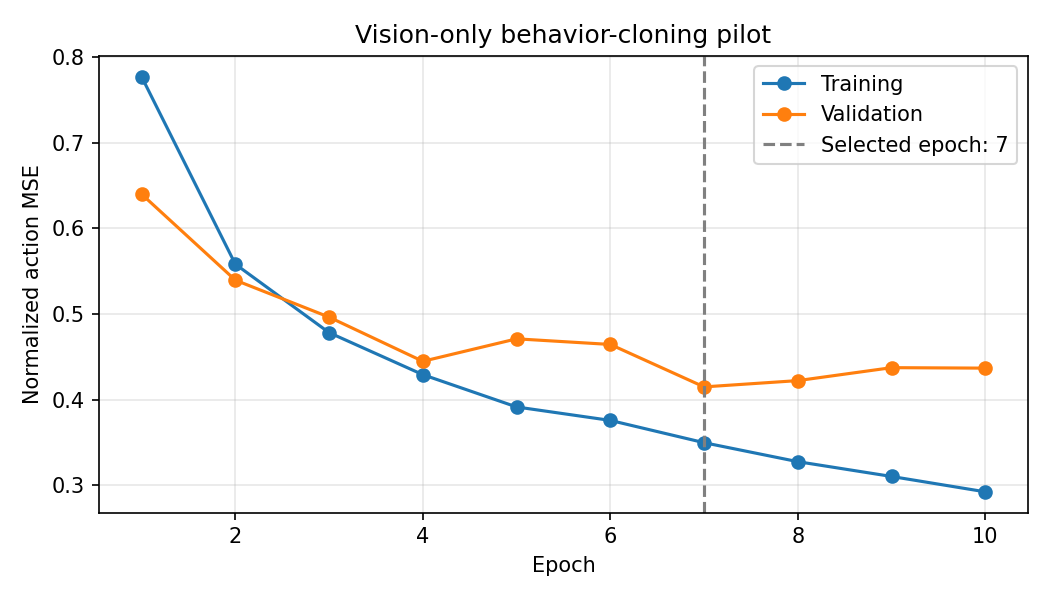

In [69]:
import matplotlib

matplotlib.use("Agg", force=True)

import matplotlib.pyplot as plt
from IPython.display import Image as NotebookImage, display

epochs = [record["epoch"] for record in history]

training_losses = [
    record["training_loss"]
    for record in history
]

validation_losses = [
    record["validation_loss"]
    for record in history
]

fig, ax = plt.subplots(figsize=(7, 4))

ax.plot(
    epochs,
    training_losses,
    marker="o",
    label="Training"
)

ax.plot(
    epochs,
    validation_losses,
    marker="o",
    label="Validation"
)

ax.axvline(
    best_epoch,
    color="gray",
    linestyle="--",
    label=f"Selected epoch: {best_epoch}"
)

ax.set_xlabel("Epoch")
ax.set_ylabel("Normalized action MSE")
ax.set_title("Vision-only behavior-cloning pilot")
ax.legend()
ax.grid(alpha=0.3)

fig.tight_layout()

plot_path = run_dir / "learning_curve.png"
fig.savefig(plot_path, dpi=150)

plt.close(fig)

display(NotebookImage(filename=str(plot_path)))

### Reload the selected checkpoint

Rebuild the architecture, restore the best saved weights, and verify validation loss. The best_model variable holds the selected policy; model may still hold the final epoch.


In [70]:
checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

assert (
    checkpoint["config"]["manifest_sha256"]
    == actual_hash
)

best_model = VisionOnlyPolicy(
    checkpoint["config"]["cameras"]
).to(device)

best_model.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True
)

best_model.eval()

reloaded_validation_loss = evaluate_loss(
    best_model,
    validation_loader,
    loss_function,
    device
)

assert math.isclose(
    reloaded_validation_loss,
    checkpoint["validation_loss"],
    rel_tol=1e-4,
    abs_tol=1e-6
)

print("Loaded epoch:", checkpoint["epoch"])
print("Saved validation MSE:", checkpoint["validation_loss"])
print("Reloaded validation MSE:", reloaded_validation_loss)
print("Checkpoint reload check passed.")

Loaded epoch: 7
Saved validation MSE: 0.4149963864021831
Reloaded validation MSE: 0.4149963864021831
Checkpoint reload check passed.


### Compare validation results by task

Measure normalized-action MSE separately for each task. Compare with always predicting the training mean action. Neither number is a task-completion rate.


In [71]:
task_totals = {
    task: {
        "model_squared_error": 0.0,
        "mean_action_squared_error": 0.0,
        "action_values": 0,
        "examples": 0,
    }
    for task in manifest["tasks"]
}

best_model.eval()

with torch.no_grad():
    for batch in validation_loader:
        images = {
            camera: batch["images"][camera].to(device)
            for camera in camera_names
        }

        targets = batch["action"].to(device)
        predictions = best_model(images)

        # Sum over the seven action components for each example.
        model_errors = (
            (predictions - targets) ** 2
        ).sum(dim=1).cpu().tolist()

        # Zero in normalized space means the training mean action.
        mean_action_errors = (
            targets ** 2
        ).sum(dim=1).cpu().tolist()

        for index, task in enumerate(batch["task"]):
            task_totals[task]["model_squared_error"] += (
                model_errors[index]
            )

            task_totals[task]["mean_action_squared_error"] += (
                mean_action_errors[index]
            )

            task_totals[task]["action_values"] += targets.shape[1]
            task_totals[task]["examples"] += 1

validation_by_task = {}

for task, totals in task_totals.items():
    model_mse = (
        totals["model_squared_error"]
        / totals["action_values"]
    )

    mean_action_mse = (
        totals["mean_action_squared_error"]
        / totals["action_values"]
    )

    validation_by_task[task] = {
        "examples": totals["examples"],
        "model_mse": model_mse,
        "constant_training_mean_mse": mean_action_mse,
    }

    print("\nTask:", task)
    print("Validation examples:", totals["examples"])
    print(f"Model MSE: {model_mse:.5f}")
    print(f"Constant mean-action MSE: {mean_action_mse:.5f}")


Task: put_the_bowl_on_the_plate
Validation examples: 568
Model MSE: 0.44168
Constant mean-action MSE: 1.05130

Task: put_the_bowl_on_the_stove
Validation examples: 584
Model MSE: 0.38904
Constant mean-action MSE: 1.00495


### Save validation results

Write selected-epoch and per-task validation results to JSON. Keep the metric and split explicit for later comparisons and reporting.


In [72]:
validation_summary = {
    "selected_epoch": checkpoint["epoch"],
    "overall_validation_mse": reloaded_validation_loss,
    "per_task": validation_by_task,
    "metric": "MSE on training-normalized action targets",
    "split": "validation",
    "manifest_sha256": actual_hash,
}

summary_path = run_dir / "validation_summary.json"

summary_path.write_text(
    json.dumps(validation_summary, indent=2),
    encoding="utf-8"
)

print("Saved:", summary_path)

Saved: /home/njmcmil/t2-project/runs/vision_only_seed0_20261117T204733_783686Z/validation_summary.json


### Convert predictions to commands

Undo action normalization using values saved in the checkpoint. This produces raw commands; simulator bounds are handled in the rollout notebook.


In [73]:
saved_normalization = checkpoint["normalization"]

action_mean_tensor = torch.tensor(
    saved_normalization["mean"],
    dtype=torch.float32,
    device=device
)

action_scale_tensor = torch.tensor(
    saved_normalization["scale"],
    dtype=torch.float32,
    device=device
)


def predict_raw_actions(model, images):
    model.eval()

    with torch.no_grad():
        normalized_actions = model(images)

        raw_actions = (
            normalized_actions * action_scale_tensor
            + action_mean_tensor
        )

    return raw_actions

### Check command conversion

Predict commands for a validation batch and compare one with its recorded target. Check shape and finite values; matching the target exactly is not expected.


In [74]:
validation_batch = next(iter(validation_loader))

validation_images = {
    camera: validation_batch["images"][camera].to(device)
    for camera in camera_names
}

raw_predictions = predict_raw_actions(
    best_model,
    validation_images
)

assert raw_predictions.shape == (
    validation_batch["action"].shape[0],
    7
)

assert torch.isfinite(raw_predictions).all()

raw_targets = (
    validation_batch["action"].to(device) * action_scale_tensor
    + action_mean_tensor
)

print("First predicted command:")
print(raw_predictions[0].cpu().numpy())

print("\nCorresponding recorded target:")
print(raw_targets[0].cpu().numpy())

print("\nAction conversion check passed.")

First predicted command:
[ 0.24770975  0.11307253  0.02204536 -0.00156402  0.00620405 -0.01380409
 -1.1937149 ]

Corresponding recorded target:
[ 0.05089286  0.         -0.01339285  0.         -0.02035714  0.
 -1.        ]

Action conversion check passed.
